## 04 · EMT-TF Expression (unconditional final notebook)

EMT transcription factors scored on THIS dataset, gated on detectable expression, spanning mesenchymal families beyond Snail/Zeb/Twist (FOXC, PRRX). VIM (vimentin) is a marker, not a TF, so it is excluded. The two most informative detectable TFs (best root-end and terminus factors) are shown as a categorical overlay of thresholded expressers on a grey manifold.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# read processed (raw expression) but reuse the manifold's pseudotime-aligned display + pseudotime
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
man = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata = adata[man.obs_names].copy()
adata.obsm['X_umap_lin'] = man.obsm['X_umap_lin']
adata.obs['t'] = man.obs['t'].values
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range %.2f -> %.2f' % (t.min(), t.max()))

cells: 65519 | pseudotime range 0.00 -> 0.01


In [4]:
# candidate EMT-TF panel (mesenchymal families; VIM excluded as a non-TF marker)
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; expr = x > 0; rho, p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print('detectable TFs (frac>0.03):', ok.TF.tolist())
print('derived pair: %s (early/root) <-> %s (late/terminus)' % (early_tf, late_tf))

    TF  frac_expr  mean_early  mean_late  rho_vs_t
 PRRX1      0.139       0.207      0.015    -0.471
  ZEB1      0.135       0.133      0.014    -0.346
 SNAI2      0.086       0.075      0.031    -0.287
TWIST2      0.042       0.044      0.003    -0.262
TWIST1      0.029       0.022      0.002    -0.214
 PRRX2      0.032       0.021      0.003    -0.194
  ZEB2      0.176       0.139      0.126    -0.114
 SNAI1      0.027       0.016      0.009    -0.081
 FOXC1      0.024       0.011      0.008    -0.054
 FOXC2      0.012       0.005      0.005    -0.024
detectable TFs (frac>0.03): ['PRRX1', 'ZEB1', 'SNAI2', 'TWIST2', 'PRRX2', 'ZEB2']
derived pair: PRRX1 (early/root) <-> ZEB2 (late/terminus)


overlay thresholds (upper quartile among expressers): {'PRRX1': 1.117, 'ZEB2': 0.918} | cells shown: {'PRRX1': 2271, 'ZEB2': 2890}
PRRX1: 13.9% expressing; 2271 shown; mean pseudotime of shown = 0.16 (all = 0.59)
ZEB2: 17.6% expressing; 2890 shown; mean pseudotime of shown = 0.57 (all = 0.59)
saved expression.pdf


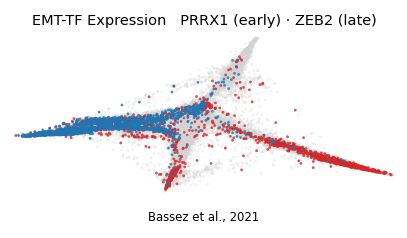

In [5]:
# categorical thresholded overlay on a grey manifold (display cutoff = upper quartile among expressers)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, size=8, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = plot[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=8, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('EMT-TF Expression   %s (early) · %s (late)' % (early_tf, late_tf), size=7.5)
ax.text(.5, -.14, 'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print('%s: %.1f%% expressing; %d shown; mean pseudotime of shown = %.2f (all = %.2f)' %
          (g, (_vec(g)>0).mean()*100, int(m.sum()), tn[m].mean(), tn.mean()))
print('saved expression.pdf')